# NASDAQ-100 の年平均成長率（CAGR）の分析と1年後の株価予測

1. データ取得（yfinance、調整後終値）
2. CAGR の分析（全期間・直近5年）
3. 個別銘柄の年次成長率
4. 複数銘柄の比較
5. 予測モデルの学習と評価（scikit-learn / LightGBM）
6. 1年後の株価・成長率の予測
7. Excel に保存

計算の処理は `src/cagr_predictor` にあり、このノートブックはそれを呼び出して表示します。
カーネルにはこのプロジェクトの `.venv` を選んでください（`uv sync` で作成されます）。

> 教育・研究目的の分析です。投資助言ではありません。

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from cagr_predictor.cagr import annual_growth, calc_cagr, yoy_table
from cagr_predictor.data import DATA_DIR, download_prices, get_nasdaq100_symbols
from cagr_predictor.features import FEATURE_COLUMNS
from cagr_predictor.plots import (
    plot_annual_returns,
    plot_cumulative_growth,
    plot_feature_importance,
    plot_growth_comparison,
    plot_model_comparison,
    plot_prediction_vs_actual,
    plot_price_history,
    plot_yoy_heatmap,
    set_style,
)
from cagr_predictor.predict import predict_price
from cagr_predictor.train import save_models, train_and_evaluate

set_style()

In [3]:
# 年次成長率を確認したい銘柄（ティッカーシンボル）
symbol = "AVGO"

# 比較したい銘柄（最大6銘柄）
tickers = ["NVDA", "AVGO", "NFLX", "META", "GOOGL", "AMZN"]

## 1. データ取得

NASDAQ-100 の構成銘柄（`data/nasdaq100.csv`）について、全期間の日足を取得します。
終値は株式分割・配当を調整した値です。

In [4]:
symbols = get_nasdaq100_symbols()
prices = download_prices(symbols, period="max")
closes = {s: df["Close"] for s, df in prices.items()}

print(f"{len(prices)} / {len(symbols)} 銘柄のデータを取得しました")

101 / 101 銘柄のデータを取得しました


## 2. CAGR の分析

In [5]:
rows = []
for s, close in closes.items():
    result = calc_cagr(close)
    rows.append(
        {
            "symbol": s,
            "start_date": result["start_date"],
            "years": result["years"],
            "cagr": result["cagr"],
            "cagr_5y": calc_cagr(close, last_years=5)["cagr"],
        }
    )
df_cagr = pd.DataFrame(rows).set_index("symbol")

# CAGR 20% 以上かつ上場16年以上の銘柄
df_top = df_cagr[(df_cagr["cagr"] >= 0.2) & (df_cagr["years"] >= 16)].sort_values("cagr", ascending=False)
df_top.style.format({"cagr": "{:.2%}", "cagr_5y": "{:.2%}", "years": "{:.1f}"})

,start_date,years,cagr,cagr_5y
symbol,,,,
TSLA,2010-06-29,16.4,39.74%,0.84%
AVGO,2009-08-06,17.3,38.41%,43.91%
NVDA,1999-01-22,27.8,35.17%,39.18%
AMZN,1997-05-15,29.5,30.53%,7.37%
FTNT,2009-11-18,17.0,29.27%,14.89%
AXON,2001-06-19,25.4,29.15%,12.03%
NFLX,2002-05-23,24.5,28.71%,-2.34%
MPWR,2004-11-19,22.0,25.90%,20.45%
MSFT,1986-03-13,40.7,24.85%,8.73%


## 3. 個別銘柄の年次成長率

- `within_year_return`: その年の初値 → 年末の騰落率
- `year_on_year_return`: 前年末 → 当年末の騰落率

In [6]:
symbol_table = annual_growth(closes[symbol])

percent = {"within_year_return": "{:.2%}", "year_on_year_return": "{:.2%}"}
symbol_table.tail(20).style.format({"first_close": "{:.2f}", "last_close": "{:.2f}", **percent}, na_rep="―")

,first_close,last_close,within_year_return,year_on_year_return
year,,,,
2009,1.13,1.28,13.04%,―
2010,1.32,2.00,51.04%,55.74%
2011,1.95,2.05,5.11%,2.85%
2012,2.06,2.29,11.25%,11.59%
2013,2.35,3.91,66.07%,70.74%
2014,3.89,7.56,94.06%,93.22%
2015,7.52,11.04,46.77%,46.04%
2016,10.82,13.64,26.14%,23.65%
2017,13.77,20.22,46.88%,48.19%


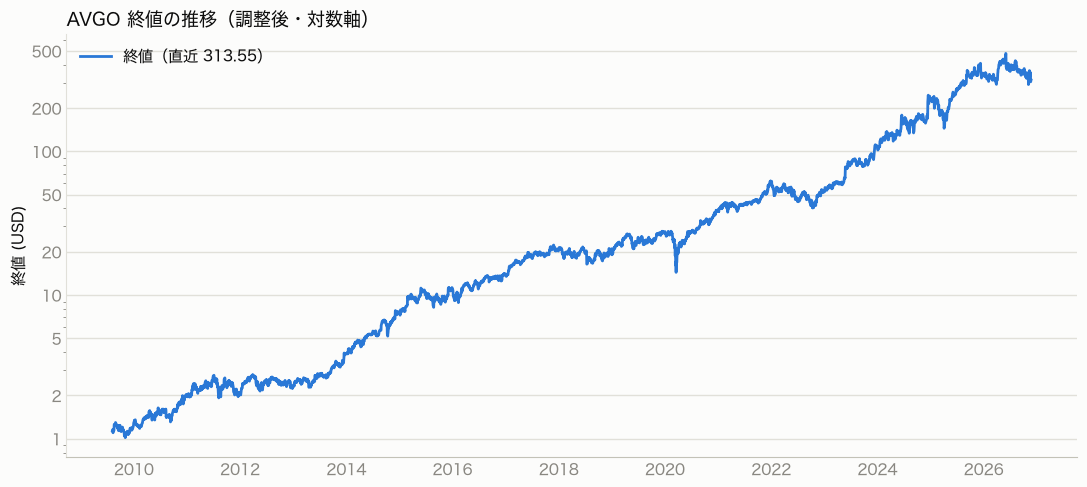

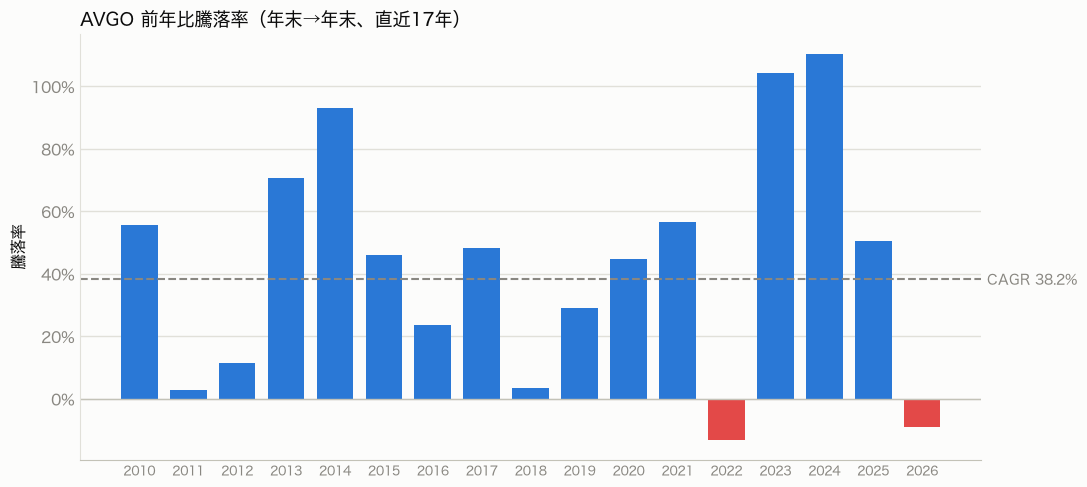

In [7]:
plot_price_history(closes[symbol], symbol)
plot_annual_returns(symbol_table, symbol)
plt.show()

## 4. 複数銘柄の比較

In [8]:
yoy = yoy_table({t: closes[t] for t in tickers})
yoy.tail(20).style.format("{:.2%}", na_rep="")

,NVDA,AVGO,NFLX,META,GOOGL,AMZN
year,,,,,,
2007,37.88%,,2.94%,,50.17%,134.77%
2008,-76.28%,,12.28%,,-55.51%,-44.65%
2009,131.47%,,84.31%,,101.52%,162.32%
2010,-17.56%,55.74%,218.93%,,-4.20%,33.81%
2011,-10.00%,2.85%,-60.56%,,8.74%,-3.83%
2012,-10.97%,11.59%,33.63%,,9.52%,44.93%
2013,33.52%,70.74%,297.63%,105.30%,58.43%,58.96%
2014,27.40%,93.22%,-7.21%,42.76%,-5.39%,-22.18%
2015,67.12%,46.04%,134.38%,34.15%,46.61%,117.78%


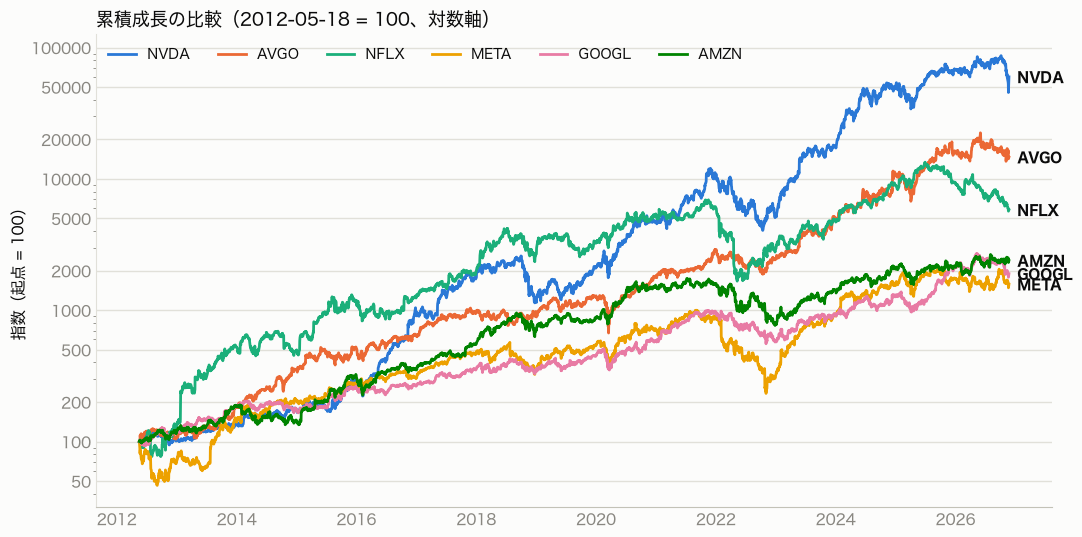

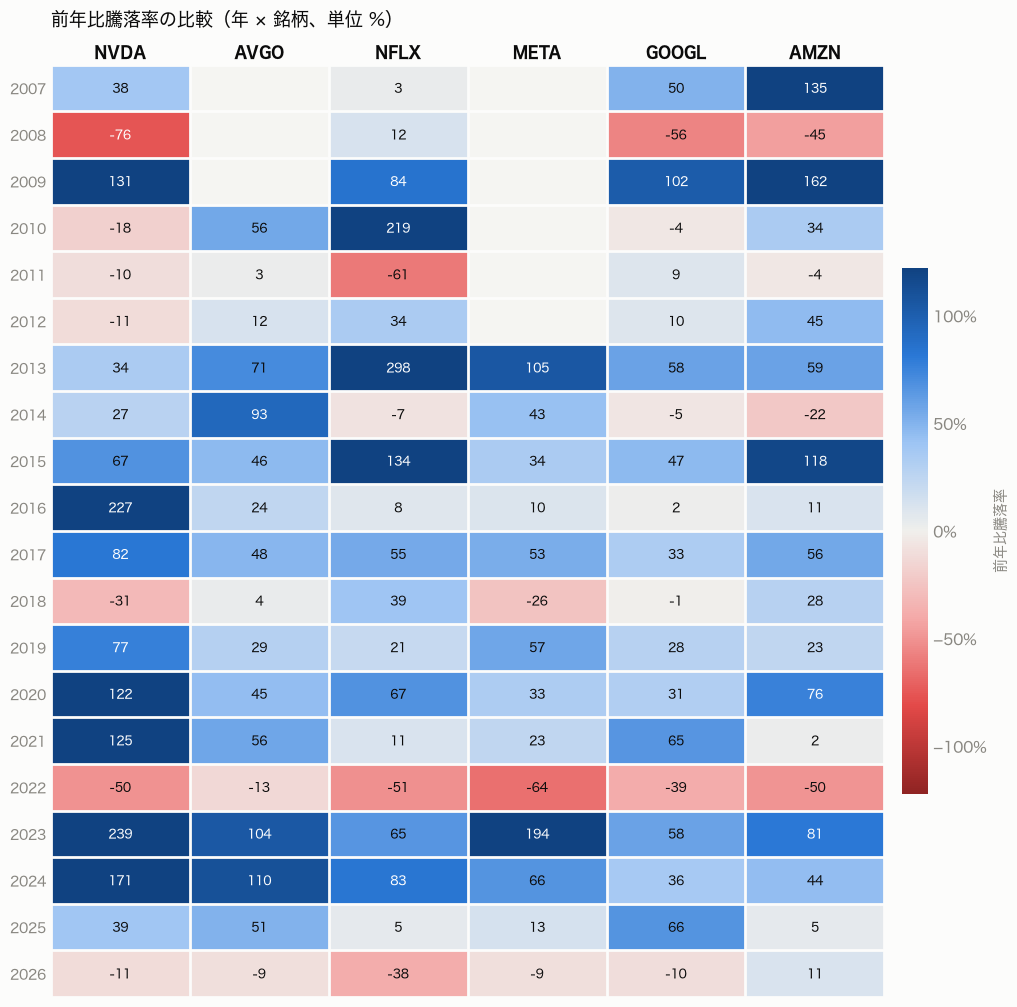

In [9]:
plot_cumulative_growth({t: closes[t] for t in tickers})
plot_yoy_heatmap(yoy)
plt.show()

## 5. 予測モデルの学習と評価

**約1年後（252営業日後）までの対数リターン**を、過去の株価・出来高から作った特徴量で予測します。

- 特徴量: 20〜252日のリターン、ボラティリティ、移動平均からの乖離率、1年高値からの下落率、出来高の比率（その日までのデータだけで計算）
- 分割: 日付で train（古い80%）と test（新しい20%）に分け、間に1年のすき間を空けて、test 期間の価格が学習に入らないようにする
- 比較: baseline（学習期間の平均リターンを常に予測）/ Ridge / RandomForest / LightGBM

学習したモデルは `models/` に保存され、API からも使われます。

In [10]:
models, metrics, test_result = train_and_evaluate(prices)
save_models(models, metrics)

print(f"train: {metrics['train_period'][0]} 〜 {metrics['train_period'][1]} ({metrics['n_train']:,} 行)")
print(f"test : {metrics['test_period'][0]} 〜 {metrics['test_period'][1]} ({metrics['n_test']:,} 行)")
pd.DataFrame(metrics["models"]).T.style.format({"mae": "{:.4f}", "rmse": "{:.4f}", "direction_accuracy": "{:.1%}"})

train: 1963-01-02 〜 2012-04-19 (391,060 行)
test : 2013-04-24 〜 2025-11-20 (272,350 行)


,mae,rmse,direction_accuracy
baseline,0.2509,0.3630,75.1%
ridge,0.2509,0.3618,75.0%
random_forest,0.2528,0.3643,74.6%
lightgbm,0.2535,0.3655,74.5%


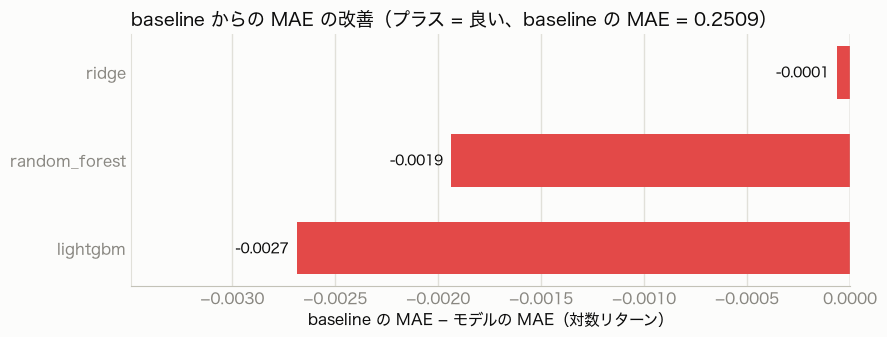

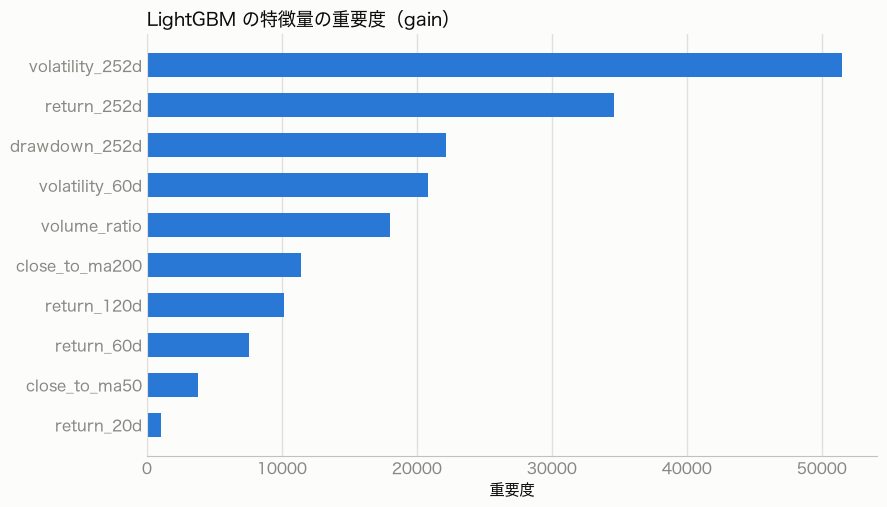

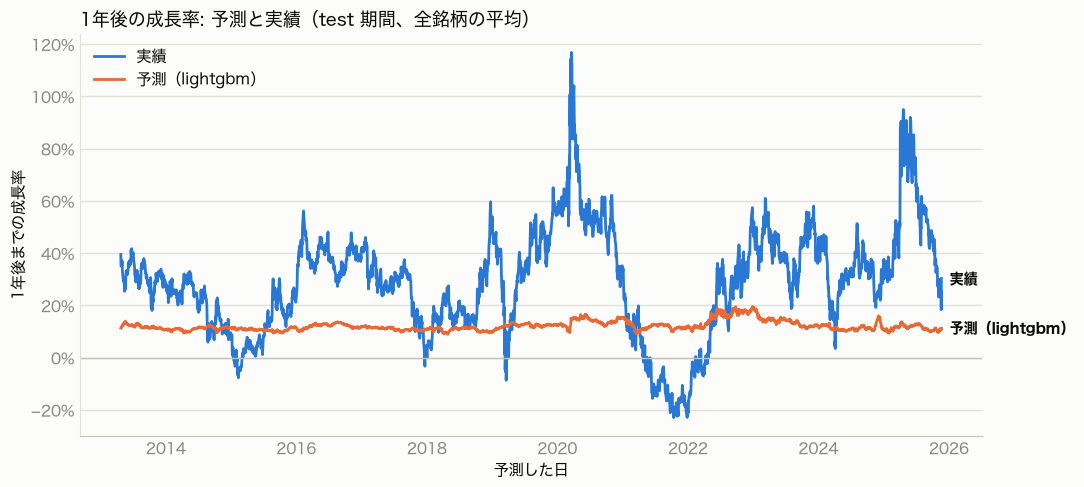

In [11]:
plot_model_comparison(metrics)
importance = pd.Series(models["lightgbm"].feature_importances_, index=FEATURE_COLUMNS)
plot_feature_importance(importance, "LightGBM の特徴量の重要度（gain）")
plot_prediction_vs_actual(test_result, "lightgbm")
plt.show()

MAE（平均絶対誤差）と RMSE は小さいほど良く、方向的中率は「上がる / 下がる」の向きが合った割合です。
方向的中率は、上昇相場が続いた期間では「常にプラスを予測する」baseline でも高くなります。

baseline との差が小さい場合、過去の株価と出来高だけでは1年後のリターンをほとんど予測できていない、ということです。
以下の予測値は参考値として扱ってください。

## 6. 1年後の株価・成長率の予測（LightGBM）

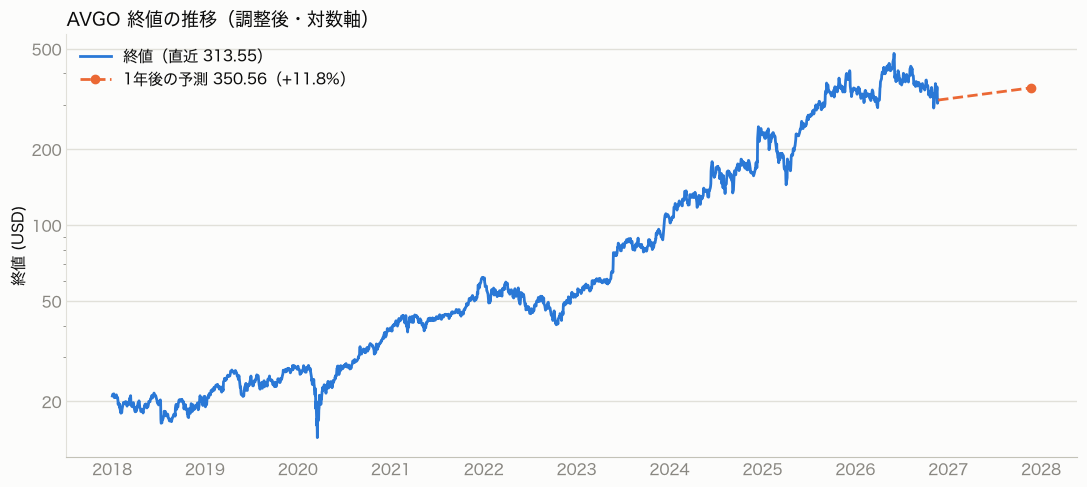

In [12]:
model = models["lightgbm"]

prediction = predict_price(prices[symbol], model)
plot_price_history(closes[symbol].loc["2018":], symbol, prediction)
plt.show()

In [13]:
# 2. で絞り込んだ銘柄について、過去5年の CAGR と今後1年の予測成長率を比べる
df_pred = pd.DataFrame(
    [{"symbol": s, **predict_price(prices[s], model)} for s in df_top.index]
).set_index("symbol")
df_pred["cagr_5y"] = df_top["cagr_5y"]

df_pred[["as_of", "last_close", "predicted_price", "predicted_growth", "cagr_5y"]].style.format(
    {"last_close": "{:.2f}", "predicted_price": "{:.2f}", "predicted_growth": "{:+.2%}", "cagr_5y": "{:.2%}"}
)

,as_of,last_close,predicted_price,predicted_growth,cagr_5y
symbol,,,,,
TSLA,2026-11-23,385.46,439.78,+14.09%,0.84%
AVGO,2026-11-23,313.55,350.56,+11.80%,43.91%
NVDA,2026-11-23,165.05,195.10,+18.20%,39.18%
AMZN,2026-11-23,255.39,278.46,+9.03%,7.37%
FTNT,2026-11-23,131.10,127.10,-3.05%,14.89%
AXON,2026-11-23,307.60,414.21,+34.66%,12.03%
NFLX,2026-11-23,58.10,67.32,+15.87%,-2.34%
MPWR,2026-11-23,1333.88,1507.51,+13.02%,20.45%
MSFT,2026-11-23,492.50,539.42,+9.53%,8.73%


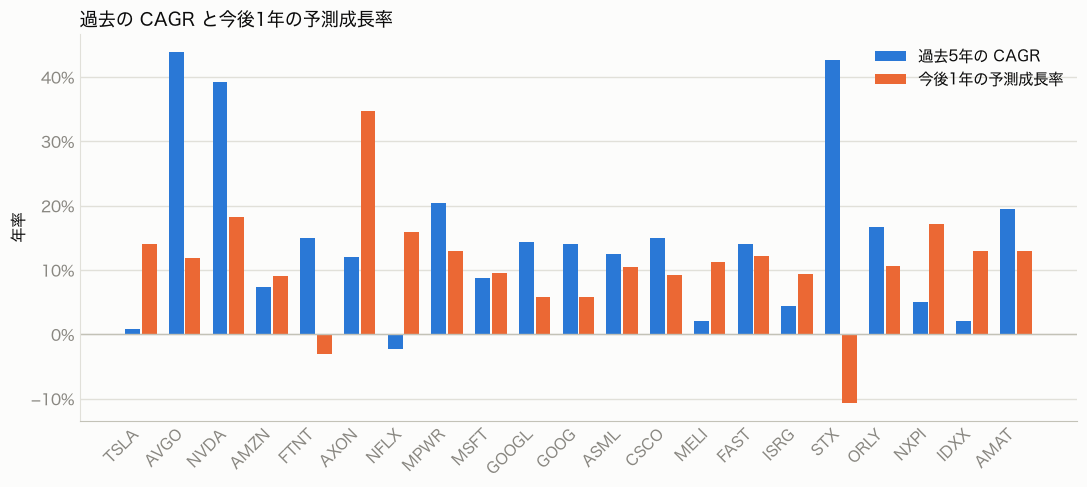

In [14]:
plot_growth_comparison(df_pred.reset_index())
plt.show()

## 7. Excel に保存

`data/analysis.xlsx` に保存します。騰落率の列は小数のまま保存し、Excel 上の表示だけ「0.00%」にします。

In [15]:
sheets = {
    "cagr": (df_cagr, ["cagr", "cagr_5y"]),
    "annual_growth": (symbol_table, ["within_year_return", "year_on_year_return"]),
    "yoy_comparison": (yoy, list(yoy.columns)),
    "prediction": (df_pred, ["predicted_return", "predicted_growth", "cagr_5y"]),
}

path = DATA_DIR / "analysis.xlsx"
with pd.ExcelWriter(path, engine="openpyxl") as writer:
    for sheet_name, (df, percent_columns) in sheets.items():
        df.to_excel(writer, sheet_name=sheet_name)
        worksheet = writer.sheets[sheet_name]
        for column in percent_columns:
            # index の列（+1）と Excel の1始まり（+1）を足して列番号にする
            column_number = df.columns.get_loc(column) + 2
            for row in range(2, worksheet.max_row + 1):
                worksheet.cell(row=row, column=column_number).number_format = "0.00%"

print(f"保存しました: {path.name}")

保存しました: analysis.xlsx
